# Week 4 (Part B): Fine-Tuned DistilBERT, Model Comparison, and SHAP
**Project:** Claude or Classifier? Cost-Aware Triage of App User Feedback, Westin Pals, MSAI-699-B01

DistilBERT (`distilbert-base-uncased`) is fine-tuned by `src/train_distilbert.py` (CPU only), which logs every run to `results/distilbert_runs.json` and saves test-set probabilities. Because training takes about an hour on a CPU, this notebook **loads those saved results** instead of retraining, then:
1. Shows the hyperparameter search (learning rate, epochs) on the validation set.
2. Compares the Week 3 baseline, the tuned TF-IDF model, and DistilBERT on the same 1,170-review test set.
3. Checks fairness and risk slices.
4. Explains DistilBERT predictions with SHAP (token-level attributions).

To retrain from scratch: `python src/train_distilbert.py` from the project root.

In [1]:
import json, os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_recall_fscore_support, accuracy_score, hamming_loss
ROOT = os.path.abspath('..'); sys.path.insert(0, os.path.join(ROOT, 'src'))
from data_prep import LABELS, APPS
R = os.path.join(ROOT, 'results')
runs = json.load(open(os.path.join(R, 'distilbert_runs.json')))
dbm = json.load(open(os.path.join(R, 'distilbert_metrics.json')))
tfm = json.load(open(os.path.join(R, 'tfidf_tuned_metrics.json')))

## 1. DistilBERT hyperparameter search (validation set, 468 reviews)

,run,epoch,train_loss,val_macro_f1,val_feature_request_f1,epoch_seconds
0,lr3e-5,1,0.347,0.854,0.727,319.335
1,lr3e-5,2,0.143,0.881,0.778,331.313
2,lr3e-5,3,0.082,0.882,0.780,328.405
3,lr5e-5,1,0.323,0.847,0.711,402.809
4,lr5e-5,2,0.128,0.876,0.768,438.387
5,lr5e-5,3,0.065,0.889,0.815,360.677


selected: lr5e-5 | best epoch 3 | val macro F1 0.889 | thresholds {'problem_report': 0.8, 'feature_request': 0.475, 'irrelevant': 0.2}


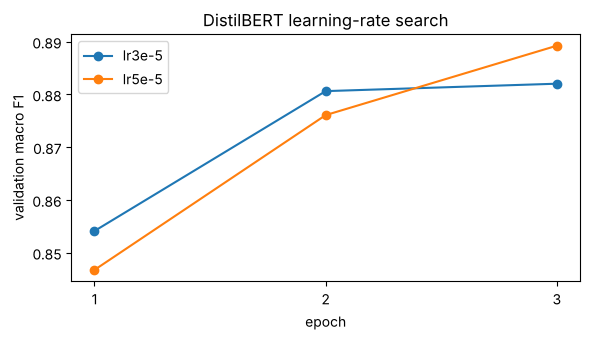

In [2]:
hist = pd.DataFrame([{'run': r['name'], 'lr': r['lr'], **h} for r in runs for h in r['history']])
display(hist[['run', 'epoch', 'train_loss', 'val_macro_f1', 'val_feature_request_f1', 'epoch_seconds']].round(3))
print('selected:', dbm['selected_run']['name'], '| best epoch', dbm['selected_run']['best_epoch'],
      '| val macro F1', round(dbm['selected_run']['best_val_macro_f1'], 3), '| thresholds', dbm['thresholds'])
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, g in hist.groupby('run'): ax.plot(g.epoch, g.val_macro_f1, marker='o', label=name)
ax.set_xlabel('epoch'); ax.set_ylabel('validation macro F1'); ax.set_xticks(sorted(hist.epoch.unique())); ax.legend(); ax.set_title('DistilBERT learning-rate search')
plt.tight_layout(); plt.savefig(os.path.join(R, 'figures', 'distilbert_lr_search.png'), dpi=150); plt.show()

## 2. Head-to-head on the held-out test set (n = 1,170)

In [3]:
def row(name, m, cost, sec):
    return {'model': name, 'macro_f1': m['macro_f1'], 'micro_f1': m['micro_f1'], 'subset_acc': m['subset_acc'],
            'problem_report_f1': m['problem_report_f1'], 'feature_request_f1': m['feature_request_f1'],
            'feature_request_p': m['feature_request_p'], 'feature_request_r': m['feature_request_r'],
            'irrelevant_f1': m['irrelevant_f1'], 'sec_per_1000_cpu': sec, 'api_usd_per_1000': cost}
base = json.load(open(os.path.join(R, 'baseline_metrics.json')))
bt = base['test']
base_m = {'macro_f1': bt['macro_f1'], 'micro_f1': bt['micro_f1'], 'subset_acc': bt['subset_accuracy'],
          **{f'{l}_f1': bt[l]['f1'] for l in LABELS}, **{f'{l}_p': bt[l]['precision'] for l in LABELS}, **{f'{l}_r': bt[l]['recall'] for l in LABELS}}
cmp = pd.DataFrame([row('Week 3 baseline TF-IDF', base_m, 0, base['inference_seconds_per_1000']),
                    row('Tuned TF-IDF (word+char, C=4)', tfm['test_tuned'], 0, tfm['inference_seconds_per_1000']),
                    row('DistilBERT (thr 0.5)', dbm['test_thr05'], 0, dbm['inference_seconds_per_1000_cpu']),
                    row('DistilBERT (tuned thr)', dbm['test_tuned_thr'], 0, dbm['inference_seconds_per_1000_cpu'])]).set_index('model')
cmp.round(3).T

model,Week 3 baseline TF-IDF,"Tuned TF-IDF (word+char, C=4)",DistilBERT (thr 0.5),DistilBERT (tuned thr)
macro_f1,0.821,0.846,0.867,0.865
micro_f1,0.847,0.877,0.893,0.891
subset_acc,0.761,0.815,0.878,0.875
problem_report_f1,0.840,0.879,0.897,0.892
feature_request_f1,0.704,0.718,0.756,0.758
feature_request_p,0.611,0.684,0.736,0.732
feature_request_r,0.830,0.755,0.777,0.786
irrelevant_f1,0.921,0.943,0.947,0.945
sec_per_1000_cpu,0.052,0.645,16.499,16.499
api_usd_per_1000,0.000,0.000,0.000,0.000


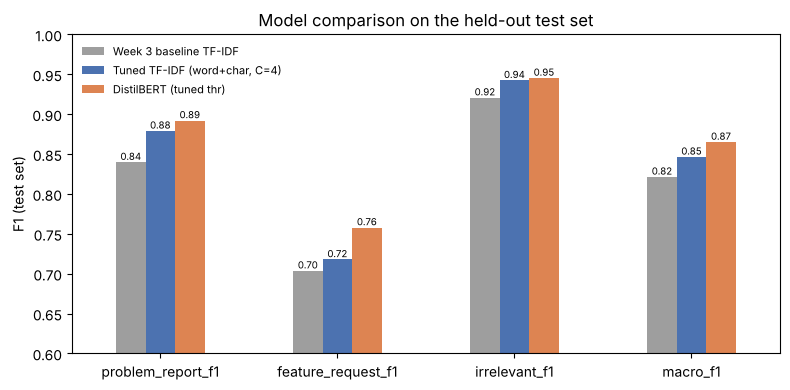

In [4]:
ax = cmp[['problem_report_f1', 'feature_request_f1', 'irrelevant_f1', 'macro_f1']].drop('DistilBERT (thr 0.5)').T.plot.bar(
    figsize=(8, 4), rot=0, ylim=(0.6, 1.0), color=['#9E9E9E', '#4C72B0', '#DD8452'])
ax.set_ylabel('F1 (test set)'); ax.set_title('Model comparison on the held-out test set'); ax.legend(loc='upper left', fontsize=8, frameon=False)
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(R, 'figures', 'model_comparison_week4.png'), dpi=150); plt.show()

## 3. Fairness and risk slices
The costliest error is a **missed problem report** (a real user issue silently ignored), so its miss rate is shown per slice for both optimized models.

In [5]:
db = pd.read_csv(os.path.join(R, 'distilbert_test_predictions.csv'))
tf = pd.read_csv(os.path.join(R, 'tfidf_tuned_test_predictions.csv'))
assert (db.review_id.values == tf.review_id.values).all()
words = db.text.str.split().str.len()
nonascii = db.text.map(lambda s: sum(ord(c) > 127 for c in s) / max(len(s), 1) > 0.2)
slices = {**{f'app: {a}': db.app == a for a in APPS}, 'length <= 3 words': words <= 3,
          'length 4-20 words': (words > 3) & (words <= 20), 'length > 20 words': words > 20, 'emoji / non-English heavy': nonascii}
rows = []
for name, m in slices.items():
    m = m.values; Y = db.loc[m, LABELS].values; pos = Y[:, 0] == 1
    r = {'slice': name, 'n': int(m.sum()), 'n_problem_reports': int(pos.sum())}
    for tag, d in [('tfidf', tf), ('distilbert', db)]:
        P = d.loc[m, [f'pred_{l}' for l in LABELS]].values
        r[f'{tag}_macro_f1'] = f1_score(Y, P, average='macro', zero_division=0)
        r[f'{tag}_PR_miss_rate'] = float(((P[:, 0] == 0) & pos).sum() / max(pos.sum(), 1))
    rows.append(r)
fair = pd.DataFrame(rows).round(3); fair

,slice,n,n_problem_reports,tfidf_macro_f1,tfidf_PR_miss_rate,distilbert_macro_f1,distilbert_PR_miss_rate
0,app: Garmin Connect,401,118,0.818,0.119,0.859,0.110
1,app: Huawei Health,389,176,0.832,0.062,0.821,0.170
2,app: Samsung Health,380,101,0.863,0.099,0.899,0.129
3,length <= 3 words,206,7,0.668,0.286,0.873,0.000
4,length 4-20 words,540,148,0.831,0.108,0.850,0.122
5,length > 20 words,424,240,0.813,0.071,0.824,0.158
6,emoji / non-English heavy,11,0,0.333,0.000,0.333,0.000


### Threshold choice is an ethical lever
The validation-tuned DistilBERT thresholds (problem report 0.80) maximize F1 but trade away problem-report recall. Lowering the problem-report threshold catches more real issues at the cost of more false alarms, which a human reviewer can dismiss cheaply.

In [6]:
Pdb = db[[f'proba_{l}' for l in LABELS]].values; Ydb = db[LABELS].values
rows = []
for t in [0.8, 0.5, 0.3]:
    pred = (Pdb[:, 0] >= t).astype(int); pos = Ydb[:, 0] == 1
    p, r, f1, _ = precision_recall_fscore_support(Ydb[:, 0], pred, average='binary', zero_division=0)
    rows.append({'problem_report_threshold': t, 'precision': p, 'recall': r, 'f1': f1,
                 'missed_problem_reports': int(((pred == 0) & pos).sum()), 'false_alarms': int(((pred == 1) & ~pos).sum())})
pd.DataFrame(rows).round(3)

,problem_report_threshold,precision,recall,f1,missed_problem_reports,false_alarms
0,0.8,0.929,0.858,0.892,56,26
1,0.5,0.913,0.881,0.897,47,33
2,0.3,0.903,0.916,0.910,33,39


## 4. SHAP explanations for DistilBERT
SHAP's text explainer masks tokens and measures how each one moves the model's probability for a label. Shown for a sample of test reviews, with the summed token attributions plotted for the feature-request output.

In [7]:
import torch, shap
from transformers import AutoTokenizer, AutoModelForSequenceClassification
MD = os.path.join(ROOT, 'models', 'distilbert_best')
tok = AutoTokenizer.from_pretrained(MD); model = AutoModelForSequenceClassification.from_pretrained(MD).eval()
def f(texts):
    enc = tok(list(texts), truncation=True, max_length=128, padding=True, return_tensors='pt')
    with torch.no_grad(): return torch.sigmoid(model(**enc).logits).numpy()
explainer = shap.Explainer(f, shap.maskers.Text(tok), output_names=LABELS)
fr = LABELS.index('feature_request'); thr = dbm['thresholds']
pred_fr, y_fr = db['pred_feature_request'].values, db['feature_request'].values
pick = {'correct feature request': np.where((y_fr == 1) & (pred_fr == 1) & (words.between(8, 30).values))[0][0],
        'correct problem report': np.where((db.problem_report.values == 1) & (db.pred_problem_report.values == 1) & (words.between(8, 30).values))[0][0],
        'false-positive feature request': np.where((y_fr == 0) & (pred_fr == 1))[0][0],
        'missed feature request': np.where((y_fr == 1) & (pred_fr == 0))[0][0]}
sv = explainer([db.text[i] for i in pick.values()], max_evals=600, batch_size=32, silent=True)
for k, (name, i) in enumerate(pick.items()):
    lab = 'problem_report' if 'problem report' in name else 'feature_request'; j = LABELS.index(lab)
    toks, vals = np.array(sv[k].data), sv[k].values[:, j]
    top = np.argsort(np.abs(vals))[-6:][::-1]
    print(f'[{name}] p({lab})={f([db.text[i]])[0, j]:.2f}  "{db.text[i][:140]}"')
    print('   top tokens:', ', '.join(f'{toks[t].strip()!r} {vals[t]:+.2f}' for t in top), '\n')

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 5971.03it/s]

[correct feature request] p(feature_request)=0.98  "I'd like to see steps added to my workout -----and show step total for Elliptical workout (though they do get added to the daily total.)"
   top tokens: 'added' +0.12, 'though' +0.10, 'added' +0.08, '(' +0.08, 'total' +0.05, 'steps' +0.05 

[correct problem report] p(problem_report)=0.99  "I could never get notifications, went to verizon,they couldn't figure it out ,also geek squad couldn't figure it out....returned it..wasted "
   top tokens: 'never' +0.21, 'notification' +0.20, 'couldn' +0.08, 'squad' +0.06, 'get' +0.05, 'couldn' +0.04 

[false-positive feature request] p(feature_request)=0.82  "Really great app with lots of data available for those of us who love to overanalyze. Insights are a great touch, as is the heart rate overl"
   top tokens: 'issues' -0.14, 'speed' +0.13, '.' +0.10, 'sync' +0.08, 'draw' +0.07, 'Only' +0.07 

[missed feature request] p(feature_request)=0.04  "1. The earlier version was about to alert me on Ca

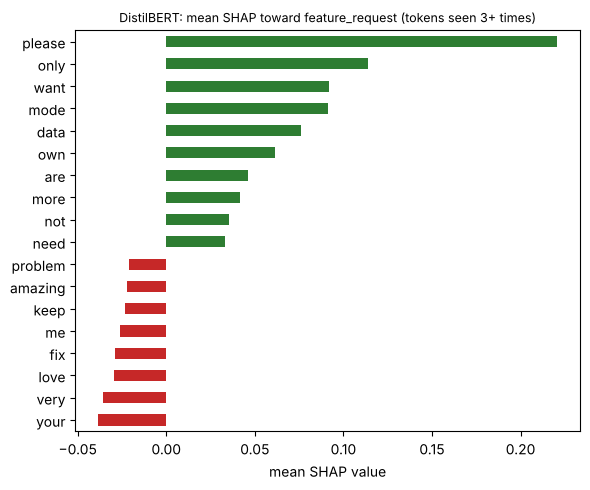

In [8]:
# Global view: average SHAP value per token across 60 test reviews, feature_request output
rng = np.random.default_rng(42); idx = rng.choice(len(db), 60, replace=False)
sv60 = explainer([db.text[i] for i in idx], max_evals=400, batch_size=32, silent=True)
agg = {}
for k in range(len(idx)):
    for t, v in zip(sv60[k].data, sv60[k].values[:, fr]):
        t = t.strip().lower()
        if t and t.isalpha(): agg.setdefault(t, []).append(v)
g = pd.Series({t: np.mean(v) for t, v in agg.items() if len(v) >= 3}).sort_values()
top = pd.concat([g.head(8), g.tail(10)])
ax = top.plot.barh(figsize=(6, 5), color=['#C62828' if v < 0 else '#2E7D32' for v in top])
ax.set_title('DistilBERT: mean SHAP toward feature_request (tokens seen 3+ times)', fontsize=9); ax.set_xlabel('mean SHAP value')
plt.tight_layout(); plt.savefig(os.path.join(R, 'figures', 'shap_distilbert_feature_request.png'), dpi=150); plt.show()
fair.to_csv(os.path.join(R, 'week4_fairness_slices.csv'), index=False); cmp.round(4).to_csv(os.path.join(R, 'week4_model_comparison.csv'))